# Projet Économétrie des Séries Temporelles — Partie Python

In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Liste des tickers à télécharger
tickers = {
    "S&P 500": "^GSPC",
    "ETF Techno": "XLK",
    "Apple": "AAPL",
    "Microsoft": "MSFT",
    "Obligations (TLT)": "TLT",
    "ETF S&P 500 (SPY)": "SPY",
    "Euro/Dollar": "EURUSD=X",
    "Bitcoin": "BTC-USD",
    "Futur Pétrole": "CL=F",
    "Or (Gold)": "GC=F"
}

# Téléchargement des données (5 dernières années)
data = {}
for nom, ticker in tickers.items():
    df = yf.download(ticker, start="2020-01-01", end="2025-01-01")
    data[nom] = df["Close"].squeeze()
    print(f"{nom} ({ticker}) téléchargé : {len(df)} lignes")


[*********************100%***********************]  1 of 1 completed


S&P 500 (^GSPC) téléchargé : 1258 lignes


[*********************100%***********************]  1 of 1 completed


ETF Techno (XLK) téléchargé : 1258 lignes


[*********************100%***********************]  1 of 1 completed


Apple (AAPL) téléchargé : 1258 lignes


... (10 outputs left out)

[*********************100%***********************]  1 of 1 completed


Futur Pétrole (CL=F) téléchargé : 1258 lignes


[*********************100%***********************]  1 of 1 completed

Or (Gold) (GC=F) téléchargé : 1258 lignes


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


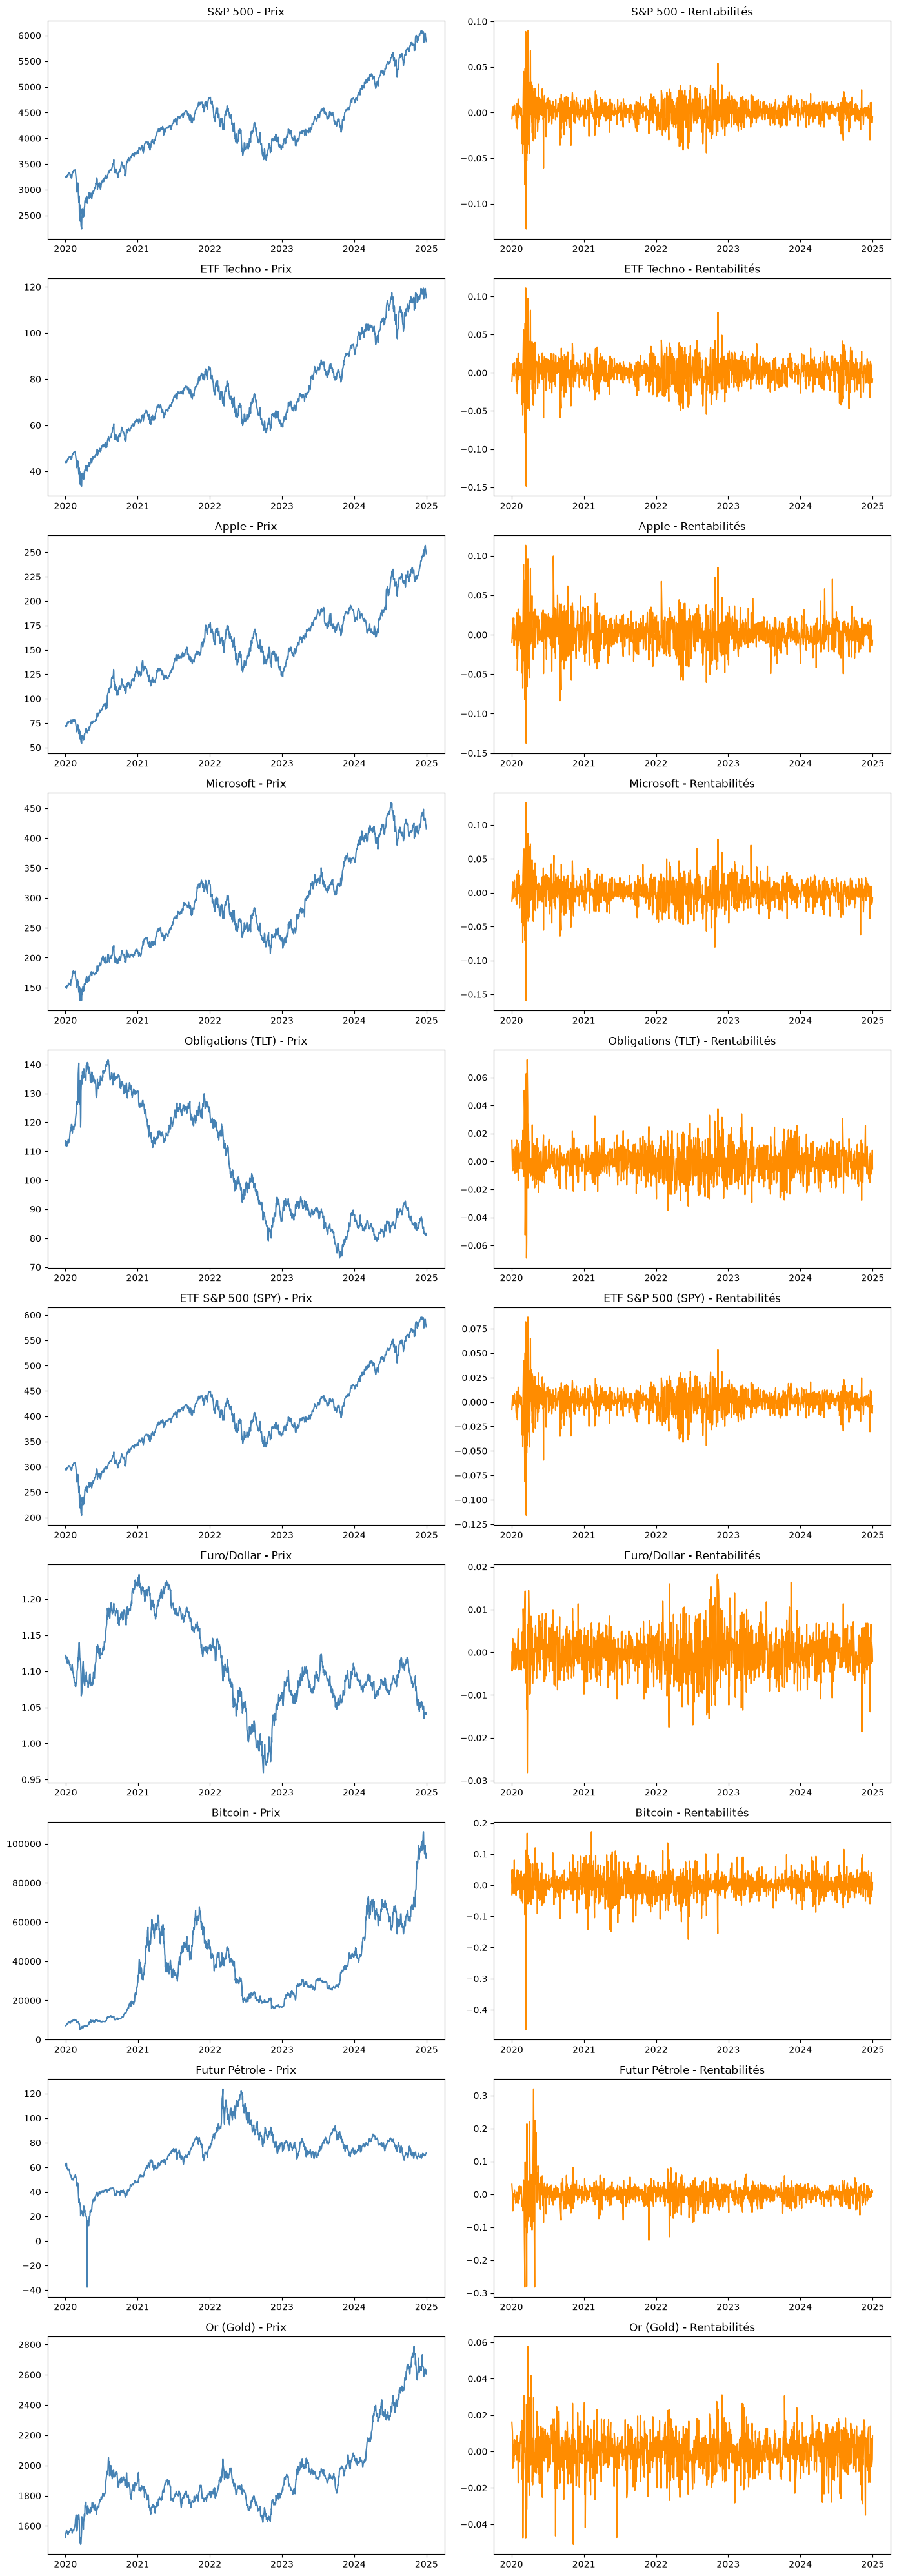

In [2]:
# Calcul des rentabilités logarithmiques
rentabilites = {}
for nom, prix in data.items():
    rentabilites[nom] = np.log(prix / prix.shift(1)).dropna()

# Graphiques : prix vs rentabilités pour chaque actif
fig, axes = plt.subplots(len(data), 2, figsize=(14, 4*len(data)))

for i, nom in enumerate(data.keys()):
    axes[i, 0].plot(data[nom], color='steelblue')
    axes[i, 0].set_title(f"{nom} - Prix")
    
    axes[i, 1].plot(rentabilites[nom], color='darkorange')
    axes[i, 1].set_title(f"{nom} - Rentabilités")

plt.tight_layout()
plt.show()


In [3]:
# Statistiques descriptives des rentabilités
stats = pd.DataFrame({
    nom: {
        "Moyenne": rentabilites[nom].mean(),
        "Écart-type": rentabilites[nom].std(),
        "Min": rentabilites[nom].min(),
        "Max": rentabilites[nom].max(),
        "Skewness": rentabilites[nom].skew(),
        "Kurtosis": rentabilites[nom].kurt()
    }
    for nom in rentabilites
}).T

print(stats.round(4))

                   Moyenne  Écart-type     Min     Max  Skewness  Kurtosis
S&P 500             0.0005      0.0135 -0.1277  0.0897   -0.8210   14.2145
ETF Techno          0.0008      0.0176 -0.1487  0.1109   -0.4144    7.8610
Apple               0.0010      0.0199 -0.1377  0.1132   -0.1125    5.3834
Microsoft           0.0008      0.0192 -0.1595  0.1329   -0.2840    7.5506
Obligations (TLT)  -0.0003      0.0113 -0.0690  0.0725    0.1247    4.0391
ETF S&P 500 (SPY)   0.0005      0.0133 -0.1159  0.0867   -0.8102   12.3721
Euro/Dollar        -0.0001      0.0047 -0.0281  0.0182   -0.1468    1.9920
Bitcoin             0.0014      0.0341 -0.4647  0.1718   -1.4007   21.4951
Futur Pétrole       0.0006      0.0337 -0.2822  0.3196    0.0383   23.8334
Or (Gold)           0.0004      0.0103 -0.0511  0.0578   -0.3200    3.6105


In [4]:
from statsmodels.tsa.arima_process import ArmaProcess

n = 500  # longueur des séries simulées
np.random.seed(42)

modeles = {
    "AR(1)": ([1, -0.6], [1]),
    "AR(2)": ([1, -0.5, 0.3], [1]),
    "AR(3)": ([1, -0.4, 0.2, -0.1], [1]),
    "MA(1)": ([1], [1, 0.7]),
    "MA(2)": ([1], [1, 0.6, 0.3]),
    "MA(3)": ([1], [1, 0.5, 0.3, 0.2]),
    "ARMA(1,1)": ([1, -0.6], [1, 0.4]),
    "ARMA(1,2)": ([1, -0.5], [1, 0.4, 0.2]),
    "ARMA(2,1)": ([1, -0.5, 0.3], [1, 0.4]),
    "ARMA(2,2)": ([1, -0.4, 0.2], [1, 0.3, 0.2]),
}

series_simulees = {}
for nom, (ar, ma) in modeles.items():
    process = ArmaProcess(ar, ma)
    series_simulees[nom] = process.generate_sample(nsample=n)
    print(f"{nom} : stationnaire = {process.isstationary}")
    

AR(1) : stationnaire = True
AR(2) : stationnaire = True
AR(3) : stationnaire = True
MA(1) : stationnaire = True
MA(2) : stationnaire = True
MA(3) : stationnaire = True
ARMA(1,1) : stationnaire = True
ARMA(1,2) : stationnaire = True
ARMA(2,1) : stationnaire = True
ARMA(2,2) : stationnaire = True


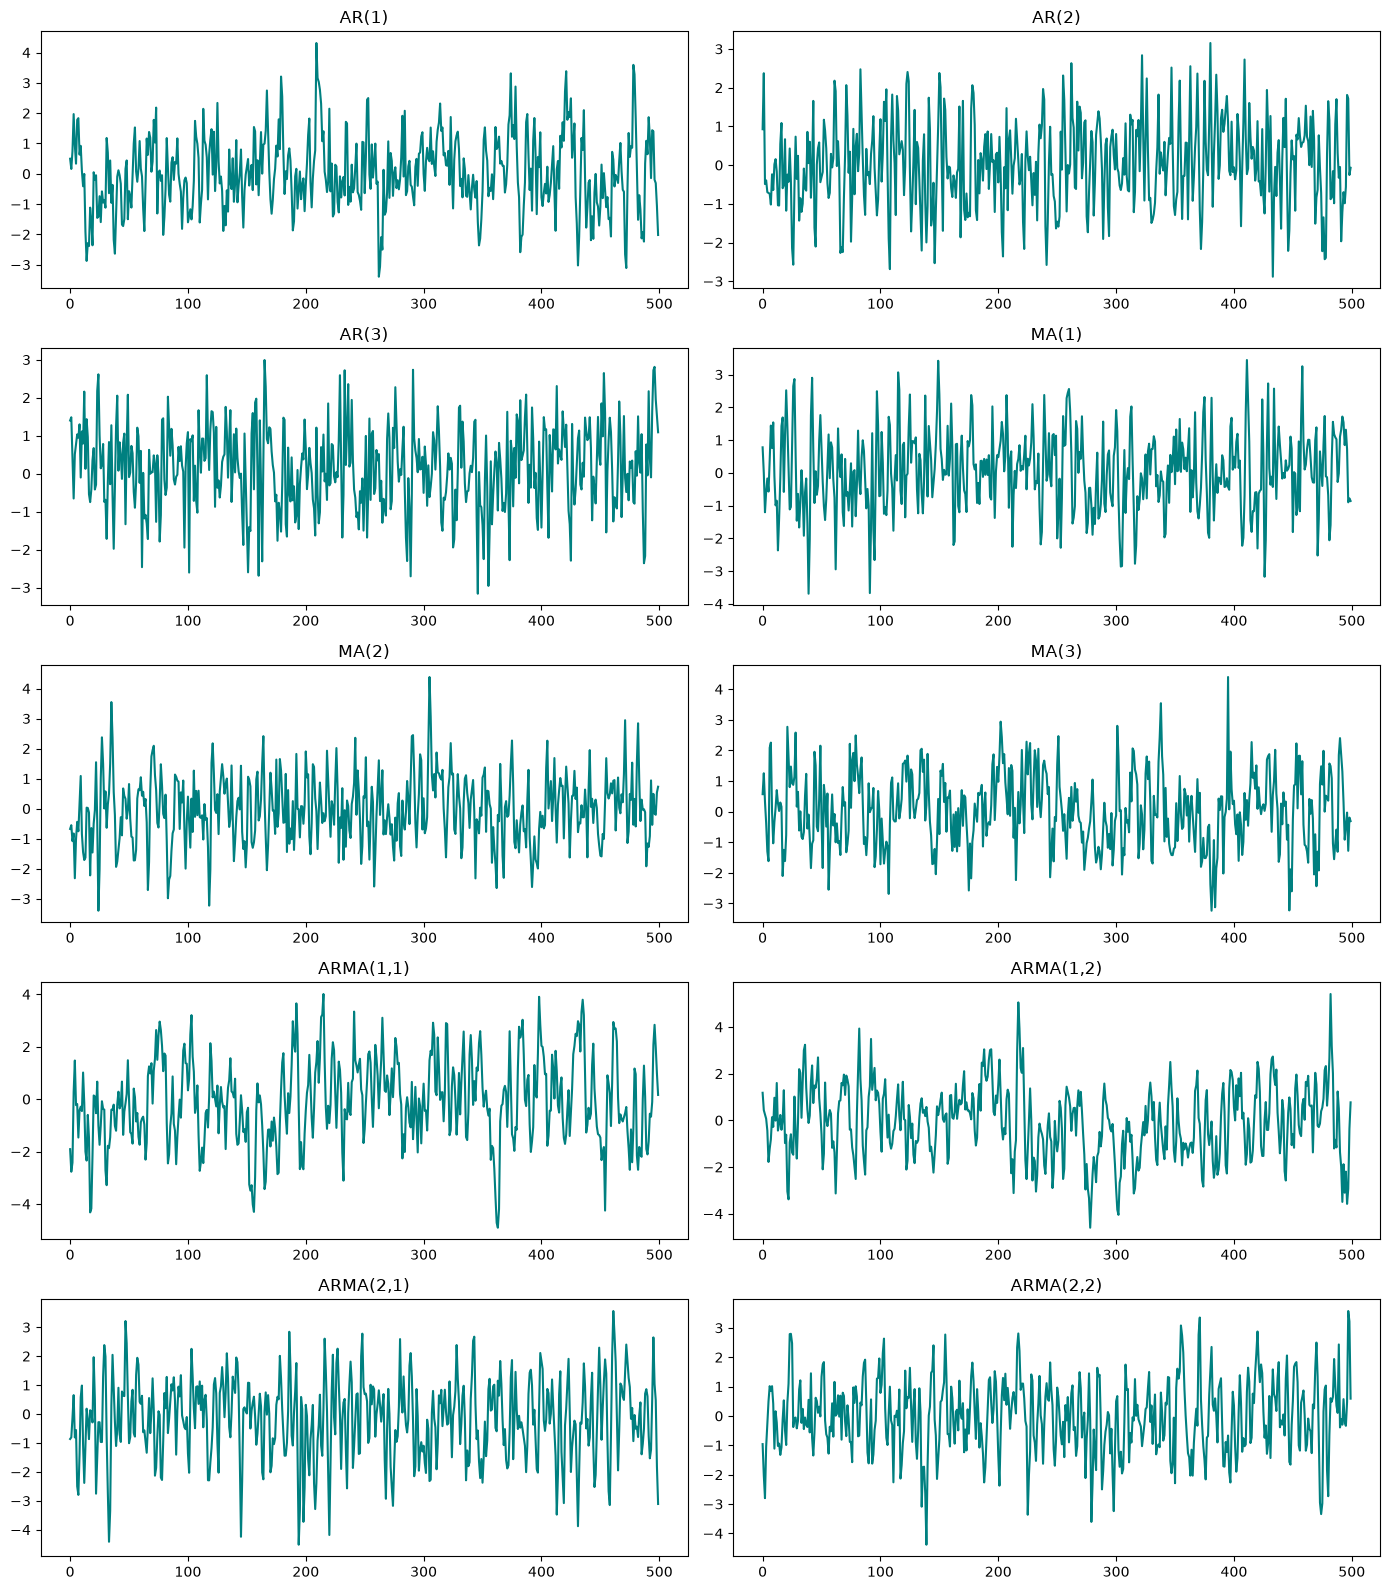

In [5]:
fig, axes = plt.subplots(5, 2, figsize=(14, 16))
axes = axes.flatten()

for i, (nom, serie) in enumerate(series_simulees.items()):
    axes[i].plot(serie, color='teal')
    axes[i].set_title(nom)

plt.tight_layout()
plt.show()


           Moyenne  Variance
AR(1)       0.0232    1.4655
AR(2)       0.0396    1.2156
AR(3)       0.1539    1.1718
MA(1)       0.0575    1.4274
MA(2)      -0.0230    1.2427
MA(3)       0.0468    1.4278
ARMA(1,1)  -0.0646    2.5498
ARMA(1,2)  -0.0642    2.3112
ARMA(2,1)  -0.1632    1.8514
ARMA(2,2)  -0.0065    1.5199


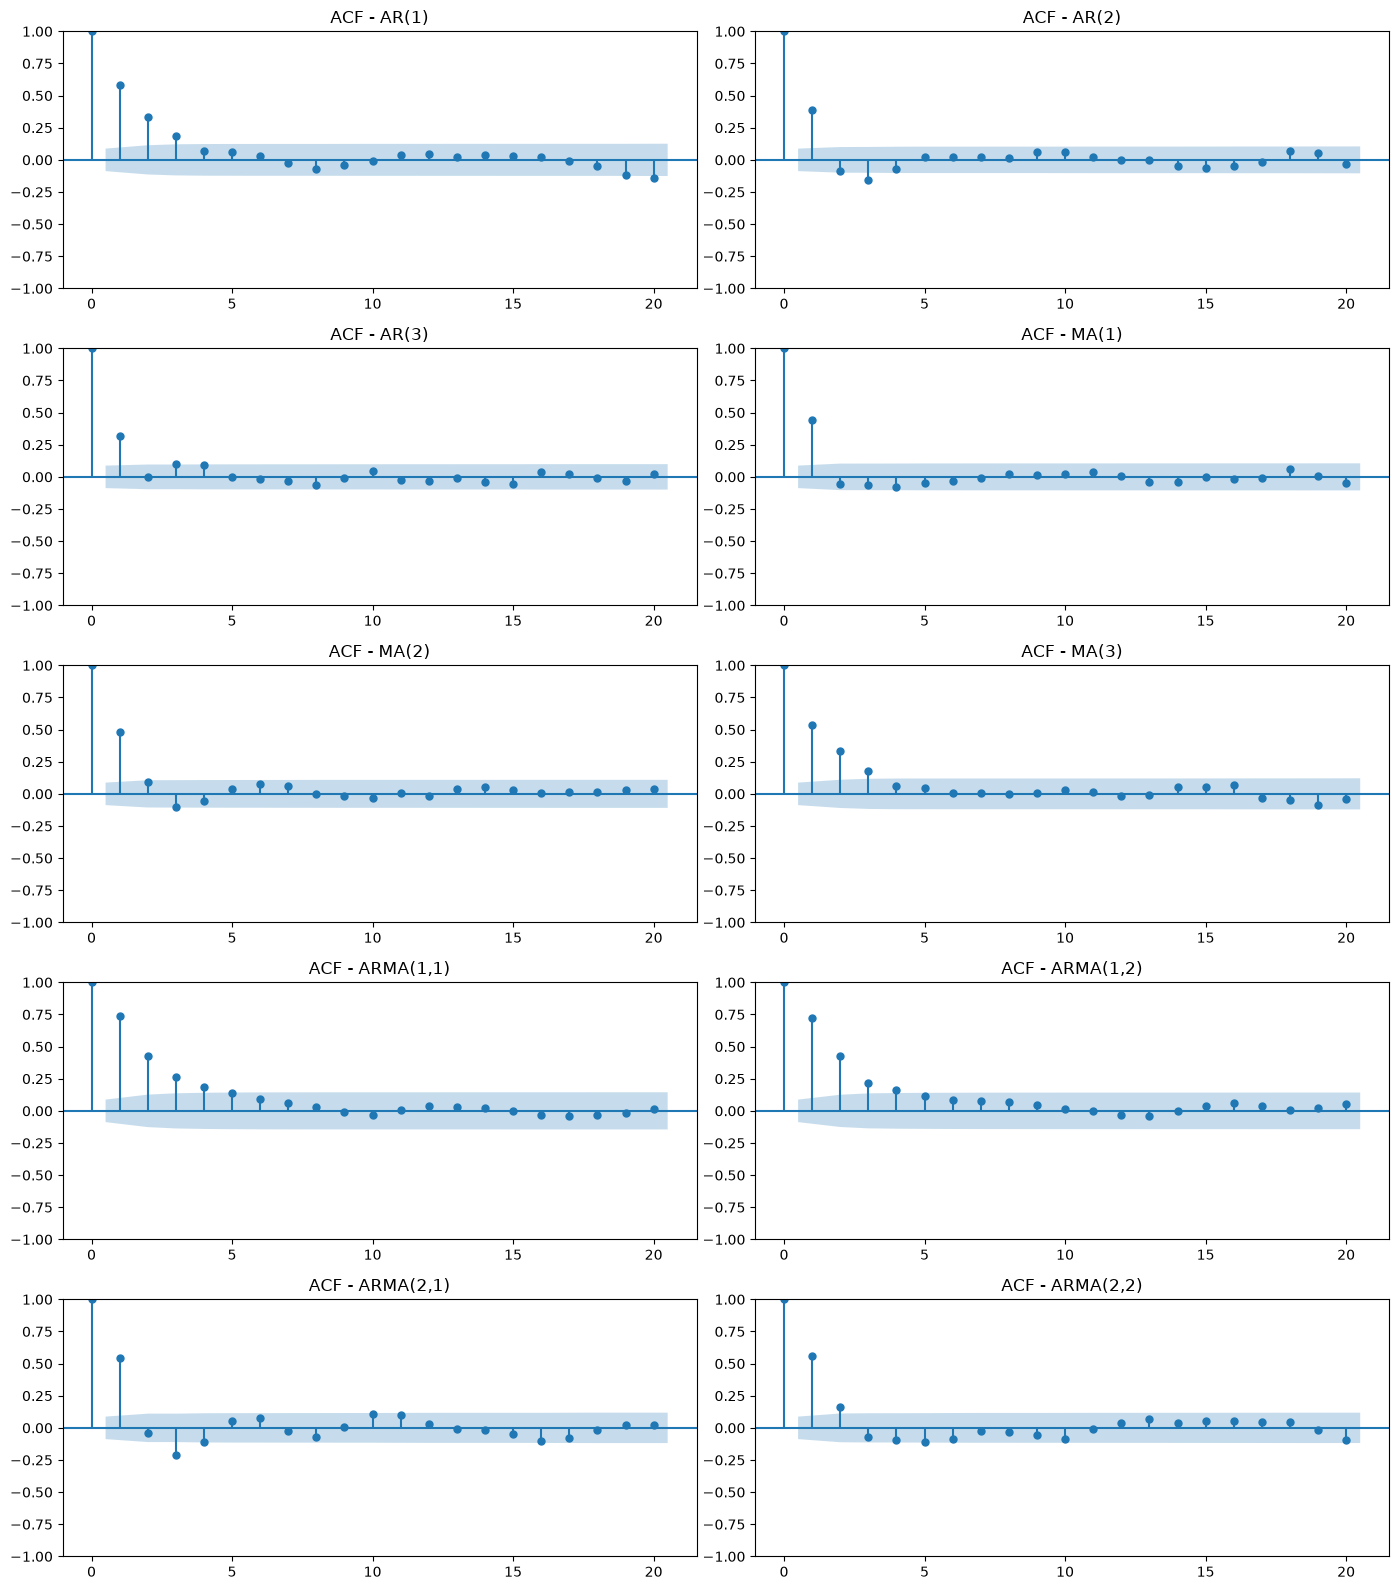

In [6]:
from statsmodels.graphics.tsaplots import plot_acf

# Propriétés statistiques
stats_simulees = pd.DataFrame({
    nom: {
        "Moyenne": serie.mean(),
        "Variance": serie.var()
    }
    for nom, serie in series_simulees.items()
}).T
print(stats_simulees.round(4))

# Corrélogrammes
fig, axes = plt.subplots(5, 2, figsize=(14, 16))
axes = axes.flatten()

for i, (nom, serie) in enumerate(series_simulees.items()):
    plot_acf(serie, ax=axes[i], lags=20, title=f"ACF - {nom}")

plt.tight_layout()
plt.show()


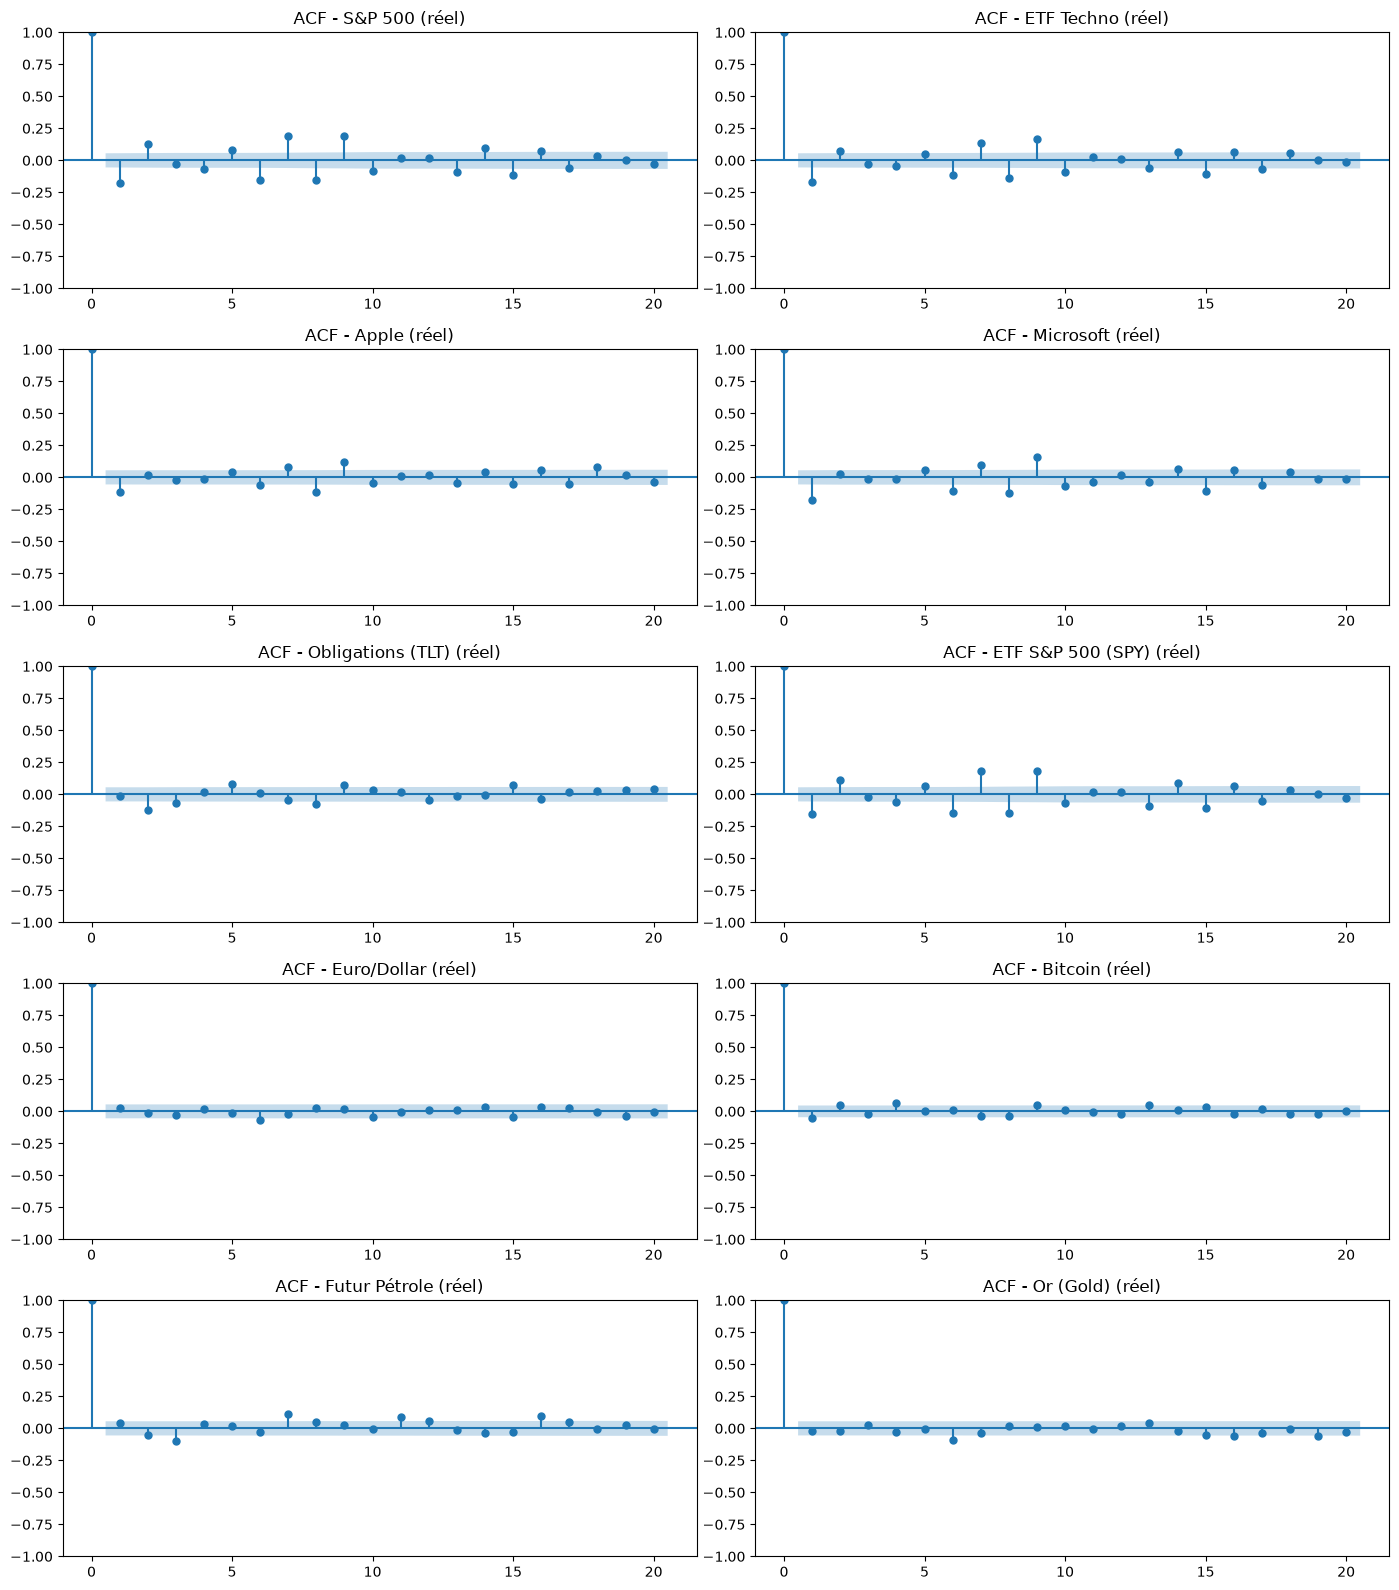

In [7]:
from statsmodels.graphics.tsaplots import plot_acf

# Corrélogrammes des rentabilités réelles
fig, axes = plt.subplots(5, 2, figsize=(14, 16))
axes = axes.flatten()

for i, nom in enumerate(rentabilites.keys()):
    plot_acf(rentabilites[nom], ax=axes[i], lags=20, title=f"ACF - {nom} (réel)")

plt.tight_layout()
plt.show()


 # 3. Comparaison
 ## 3.a — Prix vs rentabilités et stationnarité

Les graphiques de prix (Section 1.b) montrent des trajectoires avec tendance, non stationnaires : la moyenne et la variance évoluent dans le temps (ex. Or qui passe de 1600 à 2800, Pétrole avec un pic marqué en 2022). À l'inverse, les rentabilités oscillent autour d'une moyenne proche de zéro avec une variance globalement stable — un comportement typique d'une série stationnaire.

 ## 3.b — Rentabilités réelles vs séries simulées
 
Les corrélogrammes des rentabilités réelles montrent une autocorrélation quasi nulle dès le premier retard (lag), avec seulement quelques pics isolés dépassant la bande de confiance de façon marginale (ex. Futur Pétrole aux lags 7 et 15). Ce comportement se rapproche d'un bruit blanc plutôt que d'un modèle AR, MA ou ARMA structuré : contrairement aux séries simulées où l'ACF décroît progressivement sur plusieurs lags (AR) ou se coupe nettement après quelques lags (MA), les rentabilités réelles ne présentent pas de dépendance temporelle claire. Cela confirme l'hypothèse d'efficience des marchés à court terme : les rendements passés n'aident pas à prédire les rendements futurs.

# Section 4 — Automatisation 

AR(1) : stationnaire = True
AR(2) : stationnaire = True
AR(3) : stationnaire = True
MA(1) : stationnaire = True
MA(2) : stationnaire = True
MA(3) : stationnaire = True
ARMA(1,1) : stationnaire = True
ARMA(1,2) : stationnaire = True
ARMA(2,1) : stationnaire = True
ARMA(2,2) : stationnaire = True


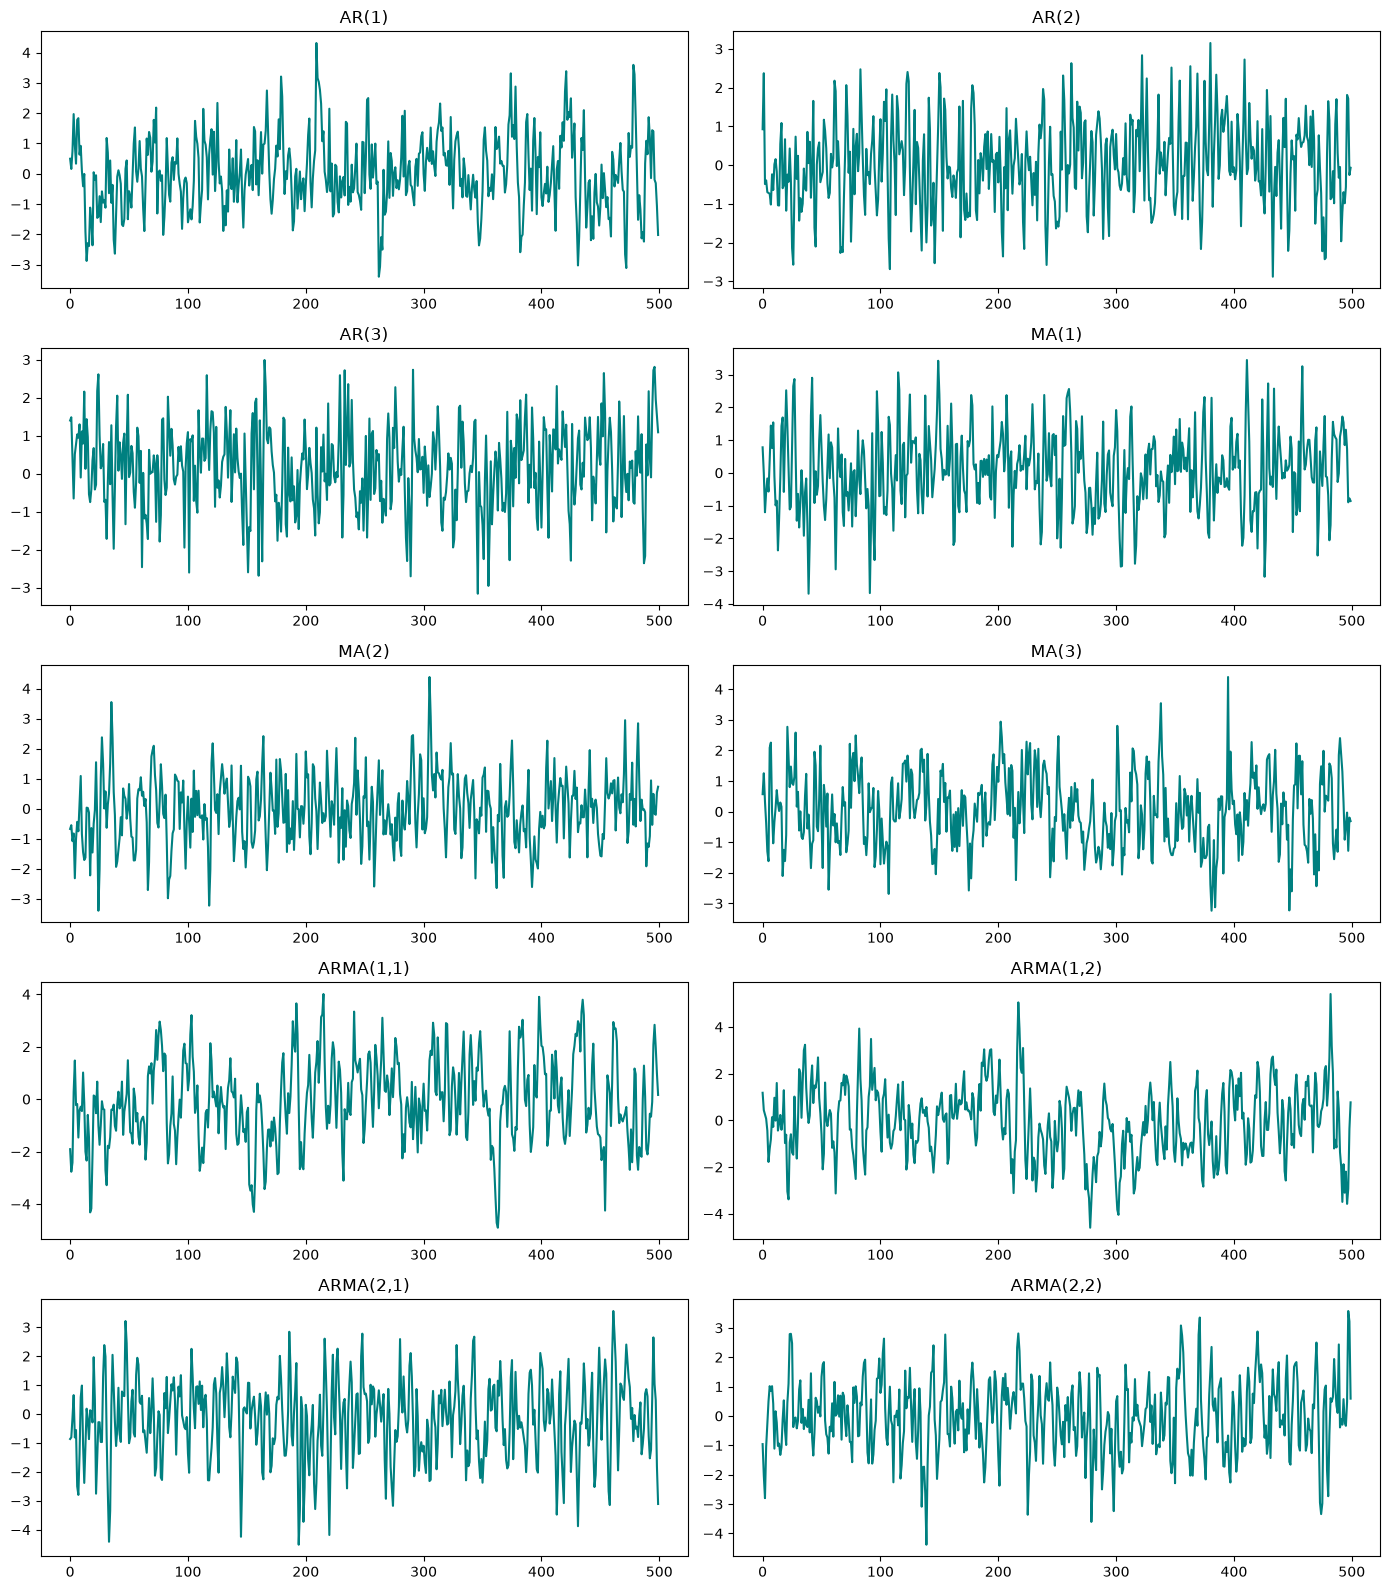

           Moyenne  Variance
AR(1)       0.0232    1.4655
AR(2)       0.0396    1.2156
AR(3)       0.1539    1.1718
MA(1)       0.0575    1.4274
MA(2)      -0.0230    1.2427
MA(3)       0.0468    1.4278
ARMA(1,1)  -0.0646    2.5498
ARMA(1,2)  -0.0642    2.3112
ARMA(2,1)  -0.1632    1.8514
ARMA(2,2)  -0.0065    1.5199


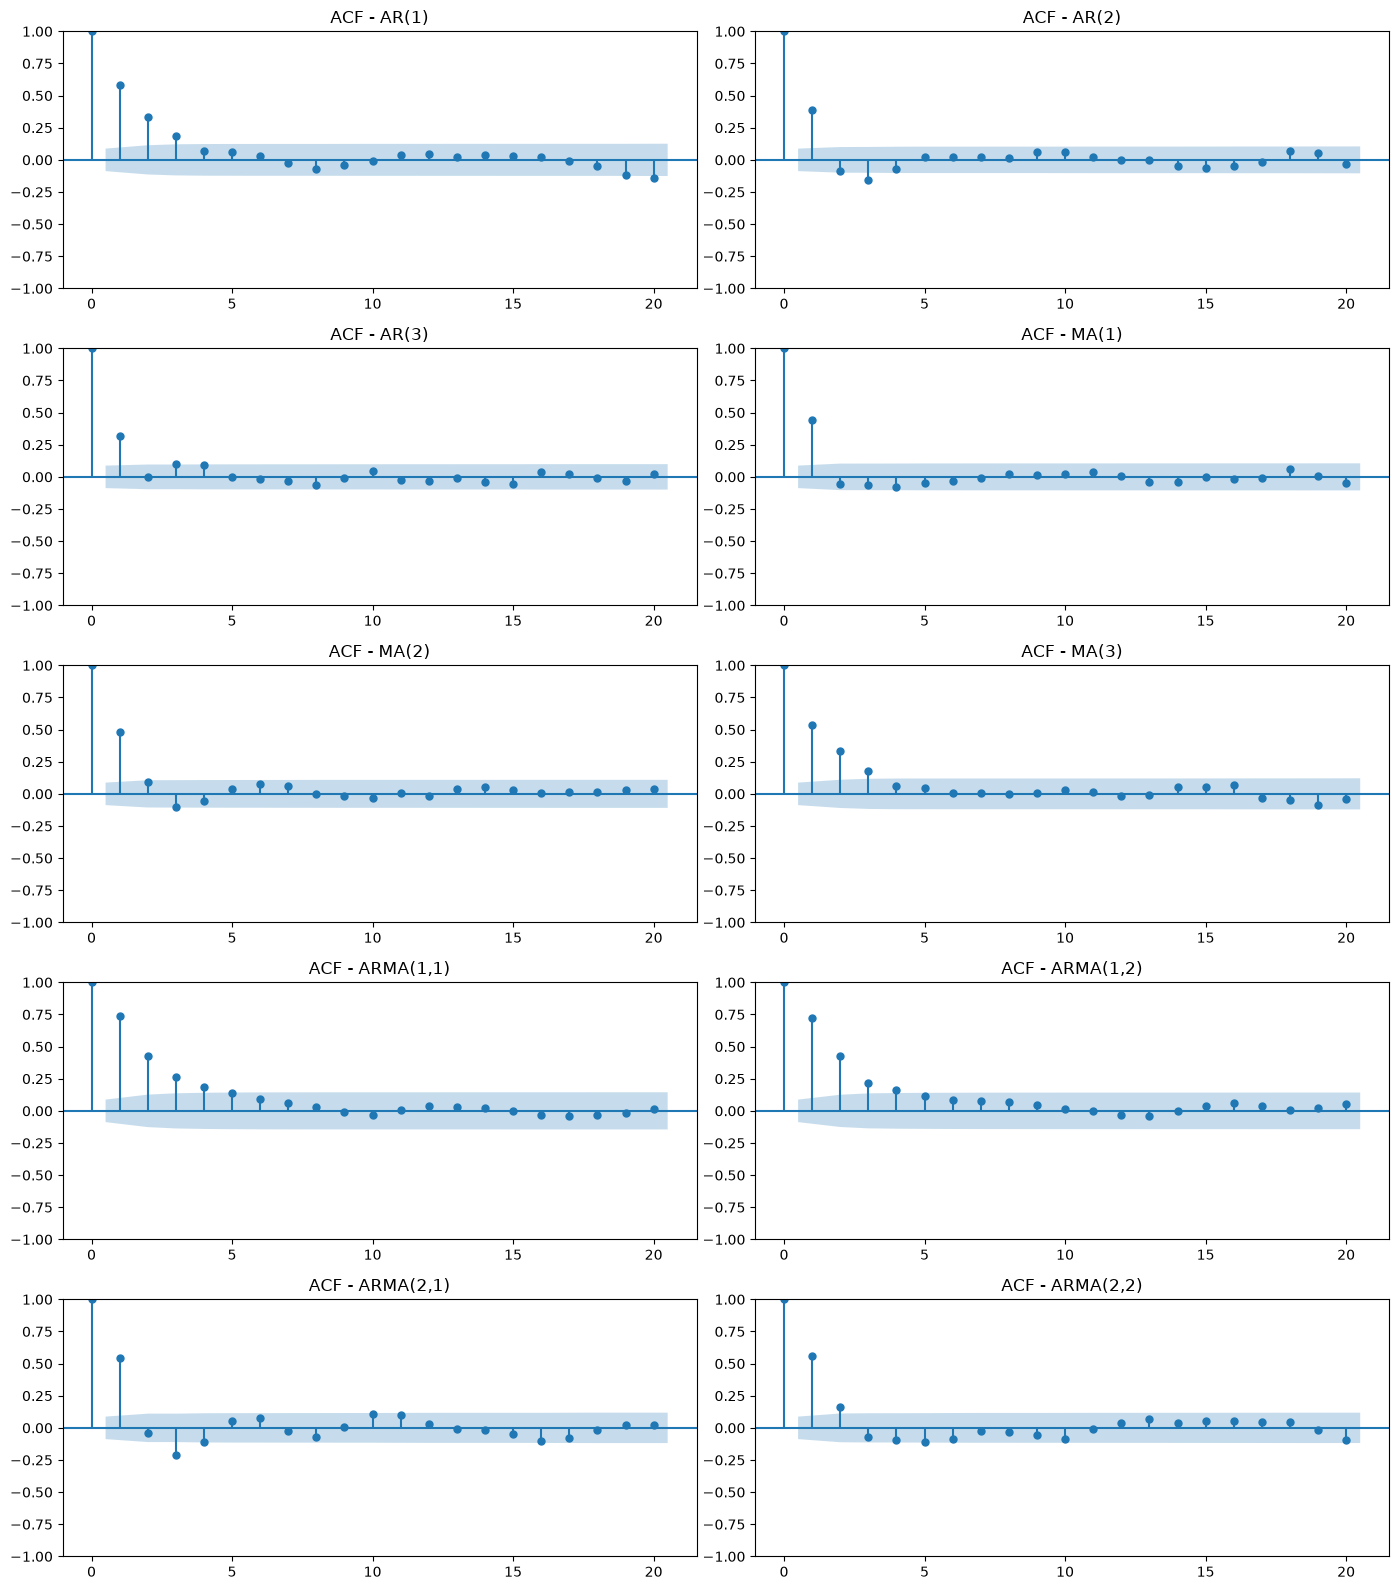

In [9]:
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf

def analyser_donnees_simulees(modeles, n=500, seed=42):
    np.random.seed(seed)
    series_simulees = {}

    for nom, (ar, ma) in modeles.items():
        process = ArmaProcess(ar, ma)
        series_simulees[nom] = process.generate_sample(nsample=n)
        print(f"{nom} : stationnaire = {process.isstationary}")

    fig, axes = plt.subplots(5, 2, figsize=(14, 16))
    axes = axes.flatten()
    for i, (nom, serie) in enumerate(series_simulees.items()):
        axes[i].plot(serie, color='teal')
        axes[i].set_title(nom)
    plt.tight_layout()
    plt.show()

    stats_simulees = pd.DataFrame({
        nom: {"Moyenne": serie.mean(), "Variance": serie.var()}
        for nom, serie in series_simulees.items()
    }).T
    print(stats_simulees.round(4))

    fig, axes = plt.subplots(5, 2, figsize=(14, 16))
    axes = axes.flatten()
    for i, (nom, serie) in enumerate(series_simulees.items()):
        plot_acf(serie, ax=axes[i], lags=20, title=f"ACF - {nom}")
    plt.tight_layout()
    plt.show()

    return series_simulees, stats_simulees


modeles = {
    "AR(1)": ([1, -0.6], [1]),
    "AR(2)": ([1, -0.5, 0.3], [1]),
    "AR(3)": ([1, -0.4, 0.2, -0.1], [1]),
    "MA(1)": ([1], [1, 0.7]),
    "MA(2)": ([1], [1, 0.6, 0.3]),
    "MA(3)": ([1], [1, 0.5, 0.3, 0.2]),
    "ARMA(1,1)": ([1, -0.6], [1, 0.4]),
    "ARMA(1,2)": ([1, -0.5], [1, 0.4, 0.2]),
    "ARMA(2,1)": ([1, -0.5, 0.3], [1, 0.4]),
    "ARMA(2,2)": ([1, -0.4, 0.2], [1, 0.3, 0.2])
}
series_simulees, stats_simulees = analyser_donnees_simulees(modeles)
